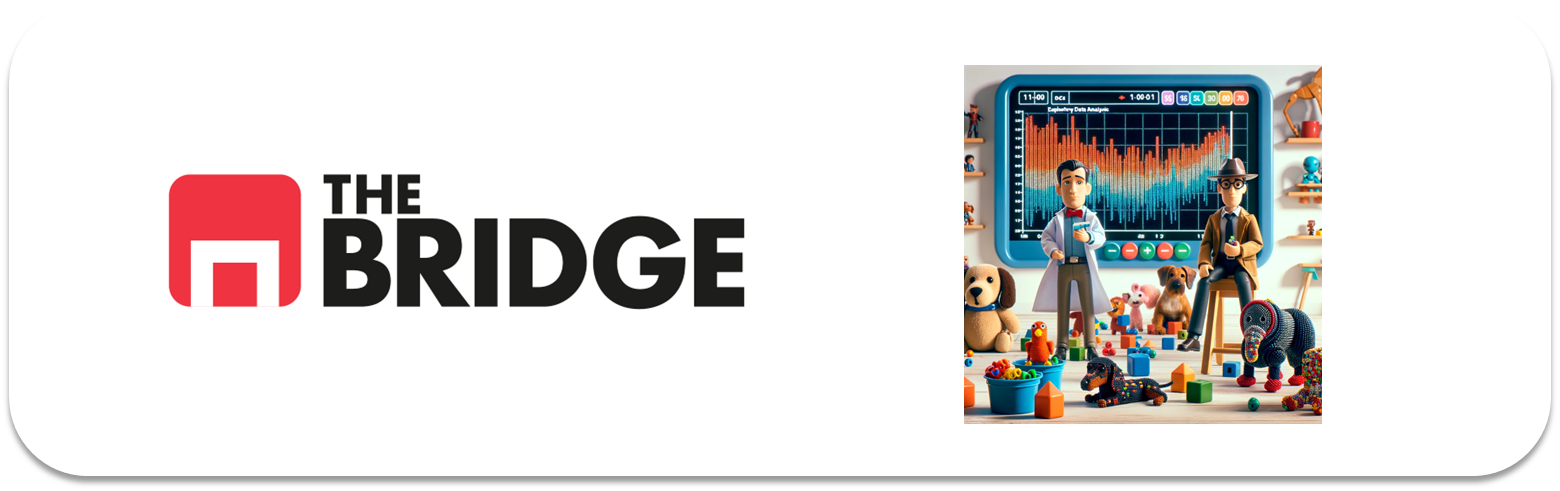

## PRACTICA OBLIGATORIA: ANÁLISIS MULTIVARIANTE

### Ejercicio 0


Importa los paquetes y módulos que necesites a lo largo del notebook

In [5]:
%pip install os

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement os (from versions: none)
ERROR: No matching distribution found for os


In [6]:
%pip install bootcampviztools

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement bootcampviztools (from versions: none)
ERROR: No matching distribution found for bootcampviztools


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import os
import bootcampviztools


In [2]:
from pathlib import Path
import sys

## #1 TITANIC

### #1.1

Carga en un dataframe el dataset del titanic, que está en la ruta "./data/titanic.csv".

In [9]:
archivo = "../data/titanic.csv"
titanic = pd.read_csv(archivo)
titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


### #1.2

Deshazte de las columnas "deck", "survived", "pclass" y "embarked" porque no las emplearemos, la primera por su cantidad de nulos y el resto porque son variantes de otras que ya existen y cuyos valores resultan más expresivos a la hora de hacer un análisis. 

In [10]:
del titanic["deck"]
del titanic["survived"]
del titanic["pclass"]
del titanic["embarked"]
titanic

,sex,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone
0,male,22.0,1,0,7.2500,Third,man,True,Southampton,no,False
1,female,38.0,1,0,71.2833,First,woman,False,Cherbourg,yes,False
2,female,26.0,0,0,7.9250,Third,woman,False,Southampton,yes,True
3,female,35.0,1,0,53.1000,First,woman,False,Southampton,yes,False
4,male,35.0,0,0,8.0500,Third,man,True,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...
886,male,27.0,0,0,13.0000,Second,man,True,Southampton,no,True
887,female,19.0,0,0,30.0000,First,woman,False,Southampton,yes,True
888,female,NaN,1,2,23.4500,Third,woman,False,Southampton,no,False
889,male,26.0,0,0,30.0000,First,man,True,Cherbourg,yes,True


### #1.3

Suma las columnas "parch" y "sibsp" para tener el número de parientes de cada pasajero, guarda el resultado en otra columna "family_members", luego deshazte de "parch" y "sibsp"

In [11]:
titanic['family_members'] = titanic['parch'] + titanic['sibsp']
titanic

,sex,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone,family_members
0,male,22.0,1,0,7.2500,Third,man,True,Southampton,no,False,1
1,female,38.0,1,0,71.2833,First,woman,False,Cherbourg,yes,False,1
2,female,26.0,0,0,7.9250,Third,woman,False,Southampton,yes,True,0
3,female,35.0,1,0,53.1000,First,woman,False,Southampton,yes,False,1
4,male,35.0,0,0,8.0500,Third,man,True,Southampton,no,True,0
...,...,...,...,...,...,...,...,...,...,...,...,...
886,male,27.0,0,0,13.0000,Second,man,True,Southampton,no,True,0
887,female,19.0,0,0,30.0000,First,woman,False,Southampton,yes,True,0
888,female,NaN,1,2,23.4500,Third,woman,False,Southampton,no,False,3
889,male,26.0,0,0,30.0000,First,man,True,Cherbourg,yes,True,0


In [12]:
del titanic['parch']
del titanic['sibsp']
titanic

,sex,age,fare,class,who,adult_male,embark_town,alive,alone,family_members
0,male,22.0,7.2500,Third,man,True,Southampton,no,False,1
1,female,38.0,71.2833,First,woman,False,Cherbourg,yes,False,1
2,female,26.0,7.9250,Third,woman,False,Southampton,yes,True,0
3,female,35.0,53.1000,First,woman,False,Southampton,yes,False,1
4,male,35.0,8.0500,Third,man,True,Southampton,no,True,0
...,...,...,...,...,...,...,...,...,...,...
886,male,27.0,13.0000,Second,man,True,Southampton,no,True,0
887,female,19.0,30.0000,First,woman,False,Southampton,yes,True,0
888,female,NaN,23.4500,Third,woman,False,Southampton,no,False,3
889,male,26.0,30.0000,First,man,True,Cherbourg,yes,True,0


### #1.4

Imputa la moda a los valores nulos de "embark_town"

In [13]:
modal = titanic['embark_town'].isna()

In [14]:

moda = titanic.embark_town.mode(dropna=True)
moda


0    Southampton
Name: embark_town, dtype: str

In [15]:
titanic.loc[modal, 'embark_town'] = 'Southampton'
titanic

,sex,age,fare,class,who,adult_male,embark_town,alive,alone,family_members
0,male,22.0,7.2500,Third,man,True,Southampton,no,False,1
1,female,38.0,71.2833,First,woman,False,Cherbourg,yes,False,1
2,female,26.0,7.9250,Third,woman,False,Southampton,yes,True,0
3,female,35.0,53.1000,First,woman,False,Southampton,yes,False,1
4,male,35.0,8.0500,Third,man,True,Southampton,no,True,0
...,...,...,...,...,...,...,...,...,...,...
886,male,27.0,13.0000,Second,man,True,Southampton,no,True,0
887,female,19.0,30.0000,First,woman,False,Southampton,yes,True,0
888,female,NaN,23.4500,Third,woman,False,Southampton,no,False,3
889,male,26.0,30.0000,First,man,True,Cherbourg,yes,True,0


### #1.5

Imputa la media a los valores faltantes de "age", si quieres puedes hacer algo más preciso (por ejemplo considerando además la columna "who")

In [16]:
filtro = titanic['who'] == 'woman'
mediana_mujer = titanic.loc[filtro, 'age'].median()
mediana_mujer

np.float64(30.0)

In [17]:
mascara = titanic['age'].isna()

In [18]:
titanic.loc[filtro & mascara, 'age'] = mediana_mujer

In [19]:
filtro2 = titanic['who'] == 'man'
mediana_hombre = titanic.loc[filtro2, 'age'].median()
mediana_hombre

np.float64(30.0)

In [20]:
titanic.loc[filtro2 & mascara, 'age'] = mediana_hombre

In [21]:
filtro3 = (titanic['sex'] == 'female') & (titanic['who'] == 'child')
mediana_nina = titanic.loc[filtro3, 'age'].median()
mediana_nina

np.float64(6.0)

In [22]:
titanic.loc[filtro3 & mascara, 'age'] = mediana_nina

In [23]:
filtro4 = (titanic['sex'] == 'male') & (titanic['who'] == 'child')
mediana_nino = titanic.loc[filtro4, 'age'].median()
mediana_nino

np.float64(4.0)

In [24]:
titanic.loc[filtro4 & mascara, 'age'] = mediana_nino

In [25]:
titanic

,sex,age,fare,class,who,adult_male,embark_town,alive,alone,family_members
0,male,22.0,7.2500,Third,man,True,Southampton,no,False,1
1,female,38.0,71.2833,First,woman,False,Cherbourg,yes,False,1
2,female,26.0,7.9250,Third,woman,False,Southampton,yes,True,0
3,female,35.0,53.1000,First,woman,False,Southampton,yes,False,1
4,male,35.0,8.0500,Third,man,True,Southampton,no,True,0
...,...,...,...,...,...,...,...,...,...,...
886,male,27.0,13.0000,Second,man,True,Southampton,no,True,0
887,female,19.0,30.0000,First,woman,False,Southampton,yes,True,0
888,female,30.0,23.4500,Third,woman,False,Southampton,no,False,3
889,male,26.0,30.0000,First,man,True,Cherbourg,yes,True,0


### 1.6

Realiza los análisis bivariantes o multivariantes que necesites, así como los test de hipótesis necesarios para contestar a las siguientes preguntas. Nota: utiliza la variable "alive" para saber si un pasajero sobrevivió o no:

In [3]:
import matplotlib.pyplot as plt
from bootcampviztools import plot_combined_graphs, pinta_distribucion_categoricas, plot_categorical_relationship_fin,\
      plot_grouped_boxplots,plot_grouped_histograms, grafico_dispersion_con_correlacion, plot_categorical_numerical_relationship
from scipy.stats import pearsonr

1. En términos absolutos, ¿sobrevivieron más hombres, mujeres o niños? ¿Y en términos relativos? ¿Existe alguna relación estadísticamente significativa entre el sexo y la supervivencia en el Titanic?¿Y entre ser adulto o ser niño?

2. En términos absolutos, ¿de que clase sobrevivieron más pasajeros?¿ Y en términos relativos? ¿Existe alguna relación estadísticamente significativa entre la clase en la que se viajaba y la supervivencia?

3. ¿De qué ciudad sobrevivieron más personas?¿Y porcentualmente de que ciudad sobrevivieron más personas? ¿Hay alguna relación estadística significativa entre haber embarcado en una de las tres ciudades y haber sobrevivido o fallecido?

4. ¿Qué relación hay entre el precio del pasaje y la supervivencia/fallecimiento?

5. Existen pasajero que no pagaron el billete, ¿podrías explicar por qué? ¿Qué ocurrió con la persona que más dinero se dejó?

6. Existe alguna relación entre el dinero pagado, la ciudad de embarque y la superviviencia/fallecimiento. No necesitas aplicar ningún test, muestralo numérica o visualmente.

7. Ahondando en la relación entre sobrevivir o fallecer, la clase en la que se viajó y la edad de los pasajeros. ¿Qué agrupación de las dos variables (clase y edad) sobrevivió más en términos absolutos y en términos relativos?

8. Finalmente, muestra las posibles relaciones entre edad, coste del billete y supervivencia/fallecimiento. ¿Qué puedes decir al respecto?

In [27]:
frec_abs = titanic.groupby('alive')['who'].value_counts()
frec_rel = titanic.groupby('alive')['who'].value_counts(normalize=True).round(4)*100
frecuencias = pd.DataFrame({'Frecuencia Absoluta':frec_abs, 'Frecuencia Relativa':frec_rel})
frecuencias

Frecuencia Absoluta  Frecuencia Relativa
alive who                                            
no    man                    449                81.79
      woman                   66                12.02
      child                   34                 6.19
yes   woman                  205                59.94
      man                     88                25.73
      child                   49                14.33

Hay una diferencia muy significativa de supervivencia de mujeres frente a mujeres y niños. Sobrevivieron el 60% de las mujeres, frente al 26% de los hombres y el 14% de los niños. Por los números de frecuencias relativas, al parecer si hay una relación de supervivencia entre el sexo y la supervivencia y entre ser adulto o niño, por las cifras anteriores.

In [28]:
fr_abs_clase = titanic.groupby('alive')['class'].value_counts()
fr_rel_clase = titanic.groupby('alive')['class'].value_counts(normalize=True).round(4)*100
frec_clase = pd.DataFrame({'Frecuencia Absoluta':fr_abs_clase, 'Frecuencia Relativa':fr_rel_clase})
frec_clase

Frecuencia Absoluta  Frecuencia Relativa
alive class                                           
no    Third                   372                67.76
      Second                   97                17.67
      First                    80                14.57
yes   First                   136                39.77
      Third                   119                34.80
      Second                   87                25.44

En términos absolutos, sobrevivieron más gente de primera clase, más que de tercera y segunda. Pero en términos relativos, la diferencia de supervivencia entre las clases es pequeña: Primera (39,77%), Tercera (34,80%) y Segunda (25,44%). Sin embargo, si nos fijamos en la tasa de mortalidad el 67,76% eran de tercera, frente a los 17,67% de segunda y los 14,57% de primera clase. Se podría decir, que los que viajaban tienen un índice de mortalidad mucho más alto que los que viajaron en primera o segunda clase.

In [29]:
fr_abs_embarque = titanic.groupby('alive')['embark_town'].value_counts()
fr_rel_embarque = titanic.groupby('alive')['embark_town'].value_counts(normalize=True).round(4)*100
frec_embarque = pd.DataFrame({'Frecuencia Absoluta':fr_abs_embarque, 'Frecuencia Relativa':fr_rel_embarque})
frec_embarque

Frecuencia Absoluta  Frecuencia Relativa
alive embark_town                                          
no    Southampton                  427                77.78
      Cherbourg                     75                13.66
      Queenstown                    47                 8.56
yes   Southampton                  219                64.04
      Cherbourg                     93                27.19
      Queenstown                    30                 8.77

Se podría decir que los que embarcaron de Southampton tienen una tasa de supervivencia mayor. Sin embargo, eso puede ser debido a que embarcaron muchás más personas en esa ciudad; ya que el índice de mortalidad también es mucho mayor en esa ciudad.

In [30]:
fr_abs_precio = titanic.groupby('alive')['fare'].value_counts()
fr_rel_precio = titanic.groupby('alive')['fare'].value_counts(normalize=True).round(4)*100
frec_precio = pd.DataFrame({'Frecuencia Absoluta':fr_abs_precio, 'Frecuencia Relativa':fr_rel_precio})
frec_precio

Frecuencia Absoluta  Frecuencia Relativa
alive fare                                             
no    8.0500                    38                 6.92
      7.8958                    37                 6.74
      13.0000                   26                 4.74
      7.7500                    22                 4.01
      26.0000                   16                 2.91
...                            ...                  ...
yes   29.7000                    1                 0.29
      39.4000                    1                 0.29
      9.3500                     1                 0.29
      13.8583                    1                 0.29
      24.0000                    1                 0.29

[330 rows x 2 columns]

No se puede concluir nada de la relacion del precio del billete y la supervivencia porque el dataframe es muy grande.

In [31]:
titanic['fare'].min()

np.float64(0.0)

Los que no pagan billete son la tripulación.

In [32]:
titanic['fare'].max()

np.float64(512.3292)

In [33]:
resultado = titanic.loc[titanic['fare'] == 512.3292, 'alive']
resultado

258    yes
679    yes
737    yes
Name: alive, dtype: str

Las 3 personas que pagaron el billete más caro sobrevivieron.

In [4]:
from scipy.stats import ttest_ind

In [46]:
# --- 1. Resumen estadístico por supervivencia y ciudad ---
resumen = titanic.groupby(['alive', 'embark_town'])['fare'].agg(['count', 'mean', 'median', 'std']).reset_index()
print("\nResumen estadístico por alive y embark:")
print(resumen)

# --- 2. Test estadístico: diferencia de precios entre sobrevivientes y no sobrevivientes ---
# Convertimos alive a booleano para el test
fare_yes = titanic.loc[titanic['alive'] == 'yes', 'fare']
fare_no = titanic.loc[titanic['alive'] == 'no', 'fare']

t_stat, p_val = ttest_ind(fare_yes, fare_no, equal_var=False)  # Welch's t-test
print(f"\nT-test entre precios de billete (alive yes vs no): t={t_stat:.3f}, p={p_val:.4f}")

if p_val < 0.05:
    print("Existe diferencia estadísticamente significativa en el precio del billete según supervivencia.")
else:
    print("No se detecta diferencia significativa en el precio del billete según supervivencia.")


Resumen estadístico por alive y embark:
  alive  embark_town  count       mean    median        std
0    no    Cherbourg     75  35.443335  14.45830  49.617218
1    no   Queenstown     47  13.335904   7.75000  13.550636
2    no  Southampton    427  20.743987  10.50000  27.896824
3   yes    Cherbourg     93  79.720926  56.92920  99.582717
4   yes   Queenstown     30  13.182227   7.80835  15.371167
5   yes  Southampton    219  39.916514  26.00000  45.383008

T-test entre precios de billete (alive yes vs no): t=6.839, p=0.0000
Existe diferencia estadísticamente significativa en el precio del billete según supervivencia.


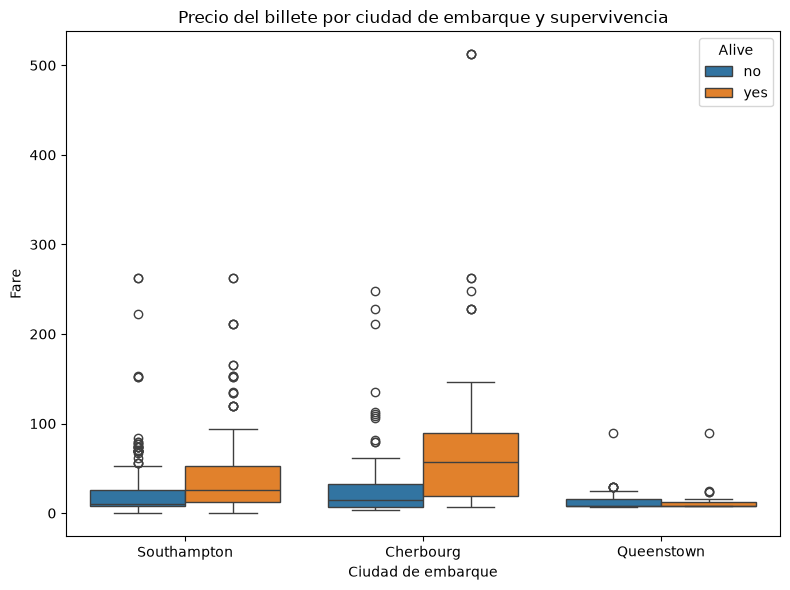

In [35]:
# --- 3. Visualización: relación entre las tres variables ---
plt.figure(figsize=(8, 6))
sns.boxplot(data=titanic, x='embark_town', y='fare', hue='alive')
plt.title("Precio del billete por ciudad de embarque y supervivencia")
plt.ylabel("Fare")
plt.xlabel("Ciudad de embarque")
plt.legend(title="Alive")
plt.tight_layout()
plt.show()

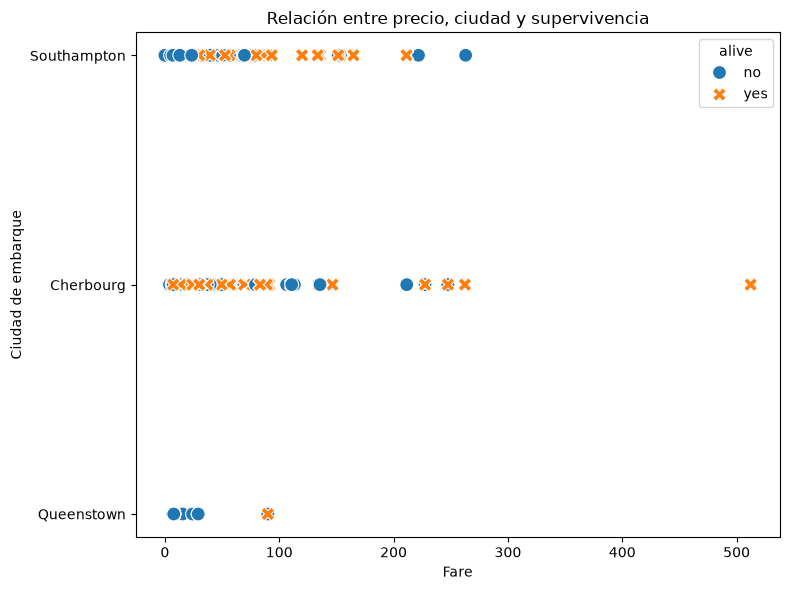

In [34]:
# --- 4. Visualización: distribución conjunta ---
plt.figure(figsize=(8, 6))
sns.scatterplot(data=titanic, x='fare', y='embark_town', hue='alive', style='alive', s=100)
plt.title("Relación entre precio, ciudad y supervivencia")
plt.xlabel("Fare")
plt.ylabel("Ciudad de embarque")
plt.tight_layout()
plt.show()

In [36]:
multi = titanic.groupby(['alive', 'class'])['age'].agg(['count', 'mean', 'median', 'std']).reset_index()
print("\nResumen estadístico por alive y class:")
print(multi)


Resumen estadístico por alive y class:
  alive   class  count       mean  median        std
0    no   First     80  40.956250    38.5  14.720216
1    no  Second     97  33.288660    30.0  11.736436
2    no   Third    372  27.500000    30.0  10.615365
3   yes   First    136  34.815588    33.5  13.129503
4   yes  Second     87  26.090000    28.0  14.514312
5   yes   Third    119  23.318655    27.0  10.974121


Según los datos, se puede ver que había mucha más gente en tercera clase que en primera y segunda clase. La edad media de los supervivientes era de casi 35 años en primera clase, de 26 años en segunda clase y 23 años los de tercera clase. Sin embargo, tenemos una desviación típica algo alta en las 3 clases que va des 11 hasta 14,5; lo que nos dice que tenemos los datos bastante dispersos, es decir, un rango de edad bastante amplio.

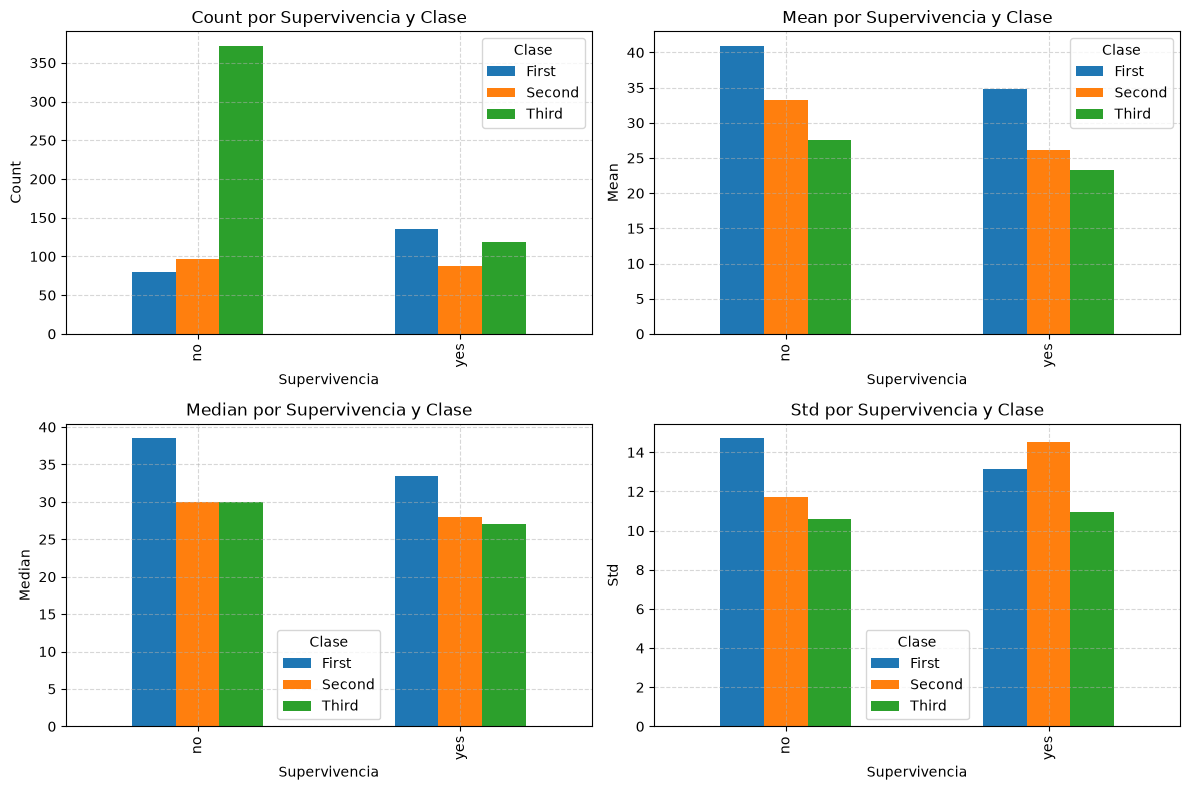

In [39]:
# Configuración de la figura
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

# Lista de métricas a graficar
metrics = ['count', 'mean', 'median', 'std']

# Graficar cada métrica
for i, metric in enumerate(metrics):
    ax = axes[i]
    # Pivot para que las clases sean columnas
    pivot_df = multi.pivot(index='alive', columns='class', values=metric)
    pivot_df.plot(kind='bar', ax=ax)
    ax.set_title(f'{metric.capitalize()} por Supervivencia y Clase')
    ax.set_ylabel(metric.capitalize())
    ax.set_xlabel('Supervivencia')
    ax.legend(title='Clase')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

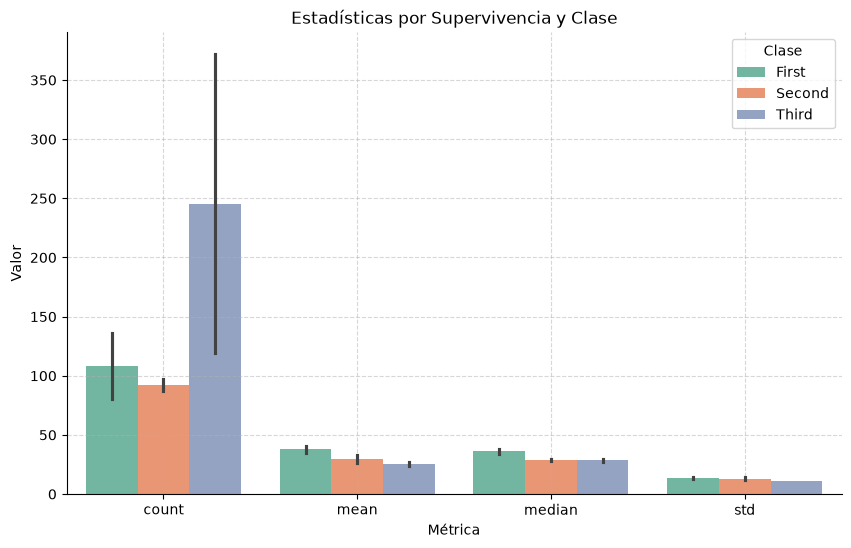

In [40]:
# Convertir a formato largo para graficar
multi_long = multi.melt(
    id_vars=['alive', 'class'], 
    value_vars=['count', 'mean', 'median', 'std'],
    var_name='metric', 
    value_name='value'
)

# Crear gráfica combinada
plt.figure(figsize=(10, 6))
sns.barplot(
    data=multi_long,
    x='metric', 
    y='value', 
    hue='class',
    palette='Set2'
)

# Añadir facetas por 'alive' usando estilo facetgrid
sns.despine()
plt.title('Estadísticas por Supervivencia y Clase')
plt.xlabel('Métrica')
plt.ylabel('Valor')
plt.legend(title='Clase')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

In [43]:
multi2 = titanic.groupby(['alive', 'age'])['fare'].agg(['count', 'mean', 'median', 'std']).reset_index()
print("\nResumen estadístico por supervivencia y coste del billete:")
print(multi2)


Resumen estadístico por supervivencia y coste del billete:
    alive   age  count        mean     median        std
0      no   1.0      2   43.293750   43.29375   5.100008
1      no   2.0      7   44.439286   29.12500  48.091874
2      no   3.0      1   21.075000   21.07500        NaN
3      no   4.0      3   29.433333   29.12500   1.708496
4      no   6.0      1   31.275000   31.27500        NaN
..    ...   ...    ...         ...        ...        ...
137   yes  58.0      3  108.844433  146.52080  71.353536
138   yes  60.0      2   77.225000   77.22500   2.793072
139   yes  62.0      2   45.250000   45.25000  49.143921
140   yes  63.0      2   43.772900   43.77290  48.345456
141   yes  80.0      1   30.000000   30.00000        NaN

[142 rows x 6 columns]


In [47]:
from IPython.display import display

In [48]:
# Filtrar por alive == 'no'
multi_no = multi2[multi2['alive'] == 'no']

# Filtrar por alive == 'yes'
multi_yes = multi2[multi2['alive'] == 'yes']

In [49]:
display(multi_no)
display(multi_yes)

,alive,age,count,mean,median,std
0,no,1.0,2,43.293750,43.29375,5.100008
1,no,2.0,7,44.439286,29.12500,48.091874
2,no,3.0,1,21.075000,21.07500,NaN
3,no,4.0,3,29.433333,29.12500,1.708496
4,no,6.0,1,31.275000,31.27500,NaN
...,...,...,...,...,...,...
72,no,66.0,1,10.500000,10.50000,NaN
73,no,70.0,2,40.750000,40.75000,42.779960
74,no,70.5,1,7.750000,7.75000,NaN
75,no,71.0,2,42.079200,42.07920,10.500536


,alive,age,count,mean,median,std
77,yes,0.42,1,8.516700,8.5167,NaN
78,yes,0.67,1,14.500000,14.5000,NaN
79,yes,0.75,2,19.258300,19.2583,0.000000
80,yes,0.83,2,23.875000,23.8750,7.247845
81,yes,0.92,1,151.550000,151.5500,NaN
...,...,...,...,...,...,...
137,yes,58.00,3,108.844433,146.5208,71.353536
138,yes,60.00,2,77.225000,77.2250,2.793072
139,yes,62.00,2,45.250000,45.2500,49.143921
140,yes,63.00,2,43.772900,43.7729,48.345456


In [50]:
# Para visualizar mejor estos datos, voy a hallar el rango de edades de los que sobreviven y los que no, es decir,
#  la diferencia entre el máximo y el mínimo de edad de ambos grupos

rango_no = (multi_no['age'].min(), multi_no['age'].max())
rango_yes = (multi_yes['age'].min(), multi_yes['age'].max())

rango_no

rango_yes

(np.float64(0.42), np.float64(80.0))

La diferencia de edad de los que no sobreviven en función del precio del billete es muy pequeña, a penas, medio año. Sin embargo, si lo estudiamos para los supervivientes, tenemos un rango muy amplio ya que es de 80 años.

## #2 Viajes

El objetivo en este caso no es tanto hacer un montón de análisis sino entender cómo de un dataset podemos obtener preguntas o hipótesis interesantes (si las hay)

### #2.1 

Carga el dataset de viajes del mes de junio. Repite el análisis bivariante entre las variables "Aircompany" e "Ingresos", mostrando previamente los viajes por compañía aérea. ¿Qué situación llamativa nos surgió? (Ten en cuenta que somos el departamenteo de DataScience de TabarAir)

In [52]:
archivo = "../Ejercicios/dataset_viajes_A.csv"
viajes = pd.read_csv(archivo)
viajes

,aircompany,origen,destino,distancia,avion,con_escala,consumo_kg,duracion,ingresos,id_vuelo,mes
0,Airnar,París,Ginebra,411,Boeing 737,False,1028.691900,51,14232.65,Air_PaGi_10737,Jun23
1,FlyQ,Bali,Roma,12738,Boeing 737,True,33479.132544,1167,468527.19,Fly_BaRo_10737,Jun23
2,TabarAir,Ginebra,Los Angeles,9103,Airbus A380,False,109439.907200,626,584789.19,Tab_GiLo_11380,Jun23
3,MoldaviAir,París,Cincinnati,6370,Boeing 737,False,17027.010000,503,233342.51,Mol_PaCi_10737,Jun23
4,TabarAir,Cincinnati,Roma,7480,Boeing 747,False,86115.744000,518,438535.07,Tab_CiRo_10747,Jun23
...,...,...,...,...,...,...,...,...,...,...,...
595,PamPangea,Bali,Londres,12553,Boeing 737,True,33310.138680,1153,442668.52,Pam_BaLo_10737,Jun23
596,Airnar,Cádiz,París,1447,Airbus A380,False,17229.139600,116,87307.63,Air_CaPa_11380,Jun23
597,Airnar,Los Angeles,Cádiz,9373,Boeing 737,False,23231.917800,731,339943.47,Air_LoCa_10737,Jun23
598,FlyQ,Barcelona,Bali,13058,Boeing 747,True,144766.211200,1070,752212.98,Fly_BaBa_10747,Jun23


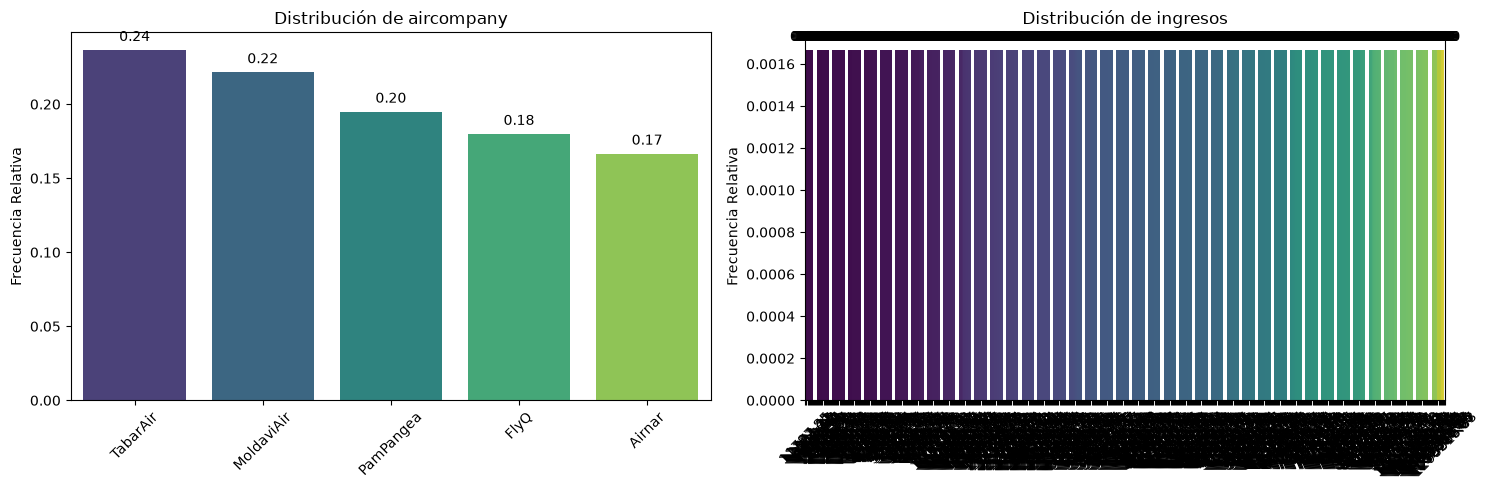

In [53]:
pinta_distribucion_categoricas(viajes,["aircompany","ingresos"], relativa= True, mostrar_valores= True)

### #2.2

Repite el análisis multivariante entre "ingresos","distancias" y "consumo_kg". ¿Qué veíamos que parecía también muy prometedor?

In [58]:
num_viajes = viajes[['ingresos', 'distancia', 'consumo_kg']].describe()
num_viajes

,ingresos,distancia,consumo_kg
count,6.000000e+02,600.000000,600.000000
mean,4.187689e+05,8071.003333,68240.520508
std,3.182858e+05,5550.244086,67441.849592
min,1.179785e+04,344.000000,835.920000
25%,1.627668e+05,3073.000000,15733.520400
50%,3.754817e+05,6877.000000,36033.998000
75%,6.188420e+05,12553.000000,111717.652800
max,1.295516e+06,20029.000000,264876.314560


In [59]:
corr = num_viajes.corr()
corr

,ingresos,distancia,consumo_kg
ingresos,1.000000,0.989327,0.985866
distancia,0.989327,1.000000,0.965553
consumo_kg,0.985866,0.965553,1.000000


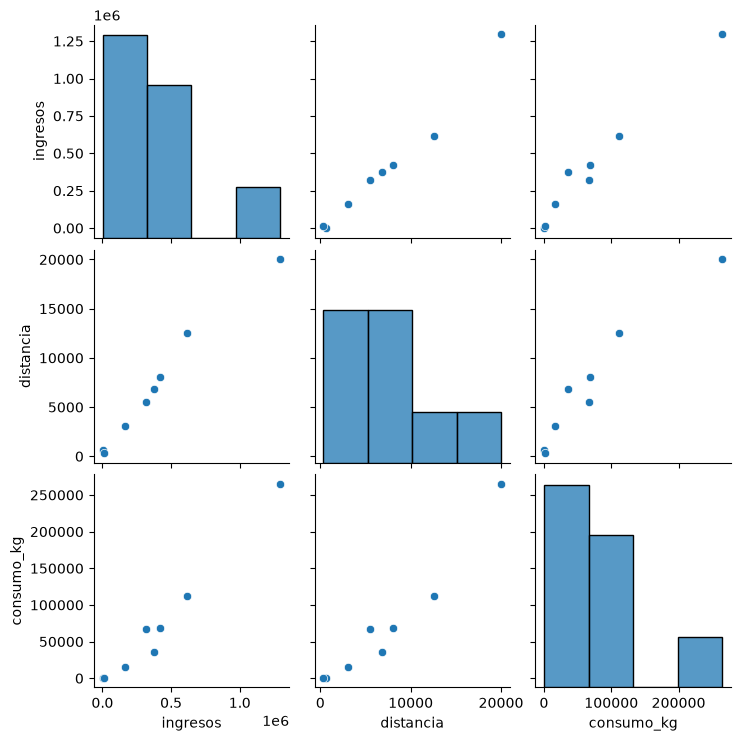

In [60]:
# Pairplot
sns.pairplot(num_viajes)
plt.show()

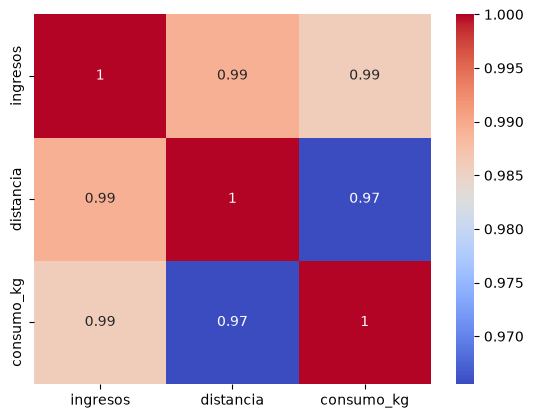

In [61]:
# Correlación
corr = num_viajes.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

Podemos concluir que los ingresos, están muy relacionados con la distancia de los vuelos y el consumo de combustible. A mayor distancia, hay un mayor consumo de combustible y también mayores ingresos.

### #2.3

Crea una variable categorica "cat_vuelo" a partir de distancias, escoge los rangos de las categorías basándote en la distribución de valores de "distancia" (sugerencia entre 3 y 4 categorías). Extra: Realiza ahora otra vez el análisis multivariante "cat_vuelo", "ingresos", "consumo_kg". ¿Ves algo diferente?

In [69]:
def categorizar_rangos(viajes, columna, etiquetas=None, num_rangos=4):
    """
    Convierte una columna numérica en categorías según rangos iguales.
    
    Parámetros:
    df          : DataFrame de entrada
    columna     : Nombre de la columna numérica a categorizar
    etiquetas   : Lista de etiquetas para los rangos (opcional)
    num_rangos  : Número de rangos (por defecto 4)
    
    Retorna:
    DataFrame con nueva columna '<columna>_categoria'
    """
        
    # Si no hay etiquetas, generar automáticamente
    if etiquetas is None:
        etiquetas = [f"Rango {i+1}" for i in range(num_rangos)]
    
    # Calcular límites automáticos
    min_val = viajes[columna].min()
    max_val = viajes[columna].max()
    bins = np.linspace(min_val, max_val, num=num_rangos+1)  # num_rangos+1 puntos
    
    # Crear nueva columna categórica
    cat_vuelo = f"{columna}_categoria"
    viajes[cat_vuelo] = pd.cut(
        viajes[columna],
        bins=bins,
        labels=etiquetas,
        include_lowest=True
    )
    
    return viajes


# Categorizar la columna 'distancia'
viajes = categorizar_rangos(viajes, 'distancia', etiquetas=['Corto', 'Medio', 'Largo', 'Muy Largo'])

viajes

,aircompany,origen,destino,distancia,avion,con_escala,consumo_kg,duracion,ingresos,id_vuelo,mes,distancia_categoria
0,Airnar,París,Ginebra,411,Boeing 737,False,1028.691900,51,14232.65,Air_PaGi_10737,Jun23,Corto
1,FlyQ,Bali,Roma,12738,Boeing 737,True,33479.132544,1167,468527.19,Fly_BaRo_10737,Jun23,Largo
2,TabarAir,Ginebra,Los Angeles,9103,Airbus A380,False,109439.907200,626,584789.19,Tab_GiLo_11380,Jun23,Medio
3,MoldaviAir,París,Cincinnati,6370,Boeing 737,False,17027.010000,503,233342.51,Mol_PaCi_10737,Jun23,Medio
4,TabarAir,Cincinnati,Roma,7480,Boeing 747,False,86115.744000,518,438535.07,Tab_CiRo_10747,Jun23,Medio
...,...,...,...,...,...,...,...,...,...,...,...,...
595,PamPangea,Bali,Londres,12553,Boeing 737,True,33310.138680,1153,442668.52,Pam_BaLo_10737,Jun23,Largo
596,Airnar,Cádiz,París,1447,Airbus A380,False,17229.139600,116,87307.63,Air_CaPa_11380,Jun23,Corto
597,Airnar,Los Angeles,Cádiz,9373,Boeing 737,False,23231.917800,731,339943.47,Air_LoCa_10737,Jun23,Medio
598,FlyQ,Barcelona,Bali,13058,Boeing 747,True,144766.211200,1070,752212.98,Fly_BaBa_10747,Jun23,Largo


In [70]:
viajes = viajes.rename(columns={'distancia_categoria':'cat_vuelo'})
viajes = viajes[["aircompany", "origen", "destino", "distancia", "cat_vuelo", "avion", "con_escala", "consumo_kg", "duracion", "ingresos", "id_vuelo", "mes"]]
viajes

,aircompany,origen,destino,distancia,cat_vuelo,avion,con_escala,consumo_kg,duracion,ingresos,id_vuelo,mes
0,Airnar,París,Ginebra,411,Corto,Boeing 737,False,1028.691900,51,14232.65,Air_PaGi_10737,Jun23
1,FlyQ,Bali,Roma,12738,Largo,Boeing 737,True,33479.132544,1167,468527.19,Fly_BaRo_10737,Jun23
2,TabarAir,Ginebra,Los Angeles,9103,Medio,Airbus A380,False,109439.907200,626,584789.19,Tab_GiLo_11380,Jun23
3,MoldaviAir,París,Cincinnati,6370,Medio,Boeing 737,False,17027.010000,503,233342.51,Mol_PaCi_10737,Jun23
4,TabarAir,Cincinnati,Roma,7480,Medio,Boeing 747,False,86115.744000,518,438535.07,Tab_CiRo_10747,Jun23
...,...,...,...,...,...,...,...,...,...,...,...,...
595,PamPangea,Bali,Londres,12553,Largo,Boeing 737,True,33310.138680,1153,442668.52,Pam_BaLo_10737,Jun23
596,Airnar,Cádiz,París,1447,Corto,Airbus A380,False,17229.139600,116,87307.63,Air_CaPa_11380,Jun23
597,Airnar,Los Angeles,Cádiz,9373,Medio,Boeing 737,False,23231.917800,731,339943.47,Air_LoCa_10737,Jun23
598,FlyQ,Barcelona,Bali,13058,Largo,Boeing 747,True,144766.211200,1070,752212.98,Fly_BaBa_10747,Jun23


In [74]:
viajes.groupby('cat_vuelo')[['ingresos', 'consumo_kg']].describe()

ingresos                                                        \
             count           mean            std        min          25%   
cat_vuelo                                                                  
Corto        176.0   74065.190455   58724.151382   11797.85   26827.7000   
Medio        217.0  355344.844194  106193.175740  193746.39  253714.2000   
Largo        116.0  692743.548190  154851.985203  409713.51  515340.1525   
Muy Largo     91.0  887447.852747  221200.423697  523861.98  613797.7600   

                                                consumo_kg                 \
                  50%           75%         max      count           mean   
cat_vuelo                                                                   
Corto       51958.385  1.063700e+05   256276.85      176.0   11113.844148   
Medio      360338.370  4.139888e+05   623089.41      217.0   52479.388464   
Largo      753867.750  7.817712e+05   958617.02      116.0  119301.755482   
Muy Largo  977234.280  1.032036e+06  1295515.83       91.0  151222.470355   

                                                                  \
                    std           min           25%          50%   
cat_vuelo                                                          
Corto      11748.414924    835.920000   2326.010725    7347.4908   
Medio      33997.707016  13660.633800  18131.238008   66155.9600   
Largo      54277.413900  30275.856000  39642.910164  144578.9548   
Muy Largo  78495.640243  39341.528928  46239.420240  192980.9648   

                                        
                    75%            max  
cat_vuelo                               
Corto       15772.08295   47872.272000  
Medio       78746.91240  123479.527200  
Largo      152345.33850  196710.388576  
Muy Largo  207395.41680  264876.314560

In [75]:
viajes.groupby('cat_vuelo')[['ingresos', 'consumo_kg']].describe().corr()

ingresos                                                    \
                     count      mean       std       min       25%       50%   
ingresos   count  1.000000 -0.812009 -0.812236 -0.807936 -0.793185 -0.819588   
           mean  -0.812009  1.000000  0.983883  0.999844  0.997146  0.999913   
           std   -0.812236  0.983883  1.000000  0.980682  0.968016  0.984316   
           min   -0.807936  0.999844  0.980682  1.000000  0.998324  0.999649   
           25%   -0.793185  0.997146  0.968016  0.998324  1.000000  0.996603   
           50%   -0.819588  0.999913  0.984316  0.999649  0.996603  1.000000   
           75%   -0.816286  0.999475  0.989114  0.998753  0.994200  0.999533   
           max   -0.792743  0.995485  0.994984  0.994025  0.987025  0.995161   
consumo_kg count  1.000000 -0.812009 -0.812236 -0.807936 -0.793185 -0.819588   
           mean  -0.843359  0.998314  0.980829  0.998025  0.994934  0.998943   
           std   -0.797059  0.991200  0.998276  0.988988  0.979532  0.991102   
           min   -0.820424  0.999882  0.983226  0.999707  0.996960  0.999980   
           25%   -0.810975  0.996099  0.964492  0.997357  0.999324  0.995952   
           50%   -0.827225  0.999437  0.987505  0.998772  0.994419  0.999728   
           75%   -0.815952  0.998763  0.991548  0.997751  0.992244  0.998848   
           max   -0.797994  0.996634  0.994259  0.995310  0.988761  0.996393   

                                     consumo_kg                                \
                       75%       max      count      mean       std       min   
ingresos   count -0.816286 -0.792743   1.000000 -0.843359 -0.797059 -0.820424   
           mean   0.999475  0.995485  -0.812009  0.998314  0.991200  0.999882   
           std    0.989114  0.994984  -0.812236  0.980829  0.998276  0.983226   
           min    0.998753  0.994025  -0.807936  0.998025  0.988988  0.999707   
           25%    0.994200  0.987025  -0.793185  0.994934  0.979532  0.996960   
           50%    0.999533  0.995161  -0.819588  0.998943  0.991102  0.999980   
           75%    1.000000  0.997604  -0.816286  0.997769  0.994704  0.999320   
           max    0.997604  1.000000  -0.792743  0.990935  0.999077  0.994529   
consumo_kg count -0.816286 -0.792743   1.000000 -0.843359 -0.797059 -0.820424   
           mean   0.997769  0.990935  -0.843359  1.000000  0.986794  0.999087   
           std    0.994704  0.999077  -0.797059  0.986794  1.000000  0.990240   
           min    0.999320  0.994529  -0.820424  0.999087  0.990240  1.000000   
           25%    0.992841  0.983474  -0.810975  0.995953  0.975675  0.996468   
           50%    0.999760  0.996037  -0.827225  0.998954  0.992930  0.999612   
           75%    0.999844  0.998489  -0.815952  0.996815  0.996313  0.998527   
           max    0.998455  0.999907  -0.797994  0.992669  0.998614  0.995843   

                                                          
                       25%       50%       75%       max  
ingresos   count -0.810975 -0.827225 -0.815952 -0.797994  
           mean   0.996099  0.999437  0.998763  0.996634  
           std    0.964492  0.987505  0.991548  0.994259  
           min    0.997357  0.998772  0.997751  0.995310  
           25%    0.999324  0.994419  0.992244  0.988761  
           50%    0.995952  0.999728  0.998848  0.996393  
           75%    0.992841  0.999760  0.999844  0.998455  
           max    0.983474  0.996037  0.998489  0.999907  
consumo_kg count -0.810975 -0.827225 -0.815952 -0.797994  
           mean   0.995953  0.998954  0.996815  0.992669  
           std    0.975675  0.992930  0.996313  0.998614  
           min    0.996468  0.999612  0.998527  0.995843  
           25%    1.000000  0.993865  0.990579  0.985653  
           50%    0.993865  1.000000  0.999413  0.997155  
           75%    0.990579  0.999413  1.000000  0.999141  
           max    0.985653  0.997155  0.999141  1.000000

C:\Users\bgran\AppData\Local\Temp\ipykernel_27844\199991974.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=stats, x='cat_vuelo', y=('ingresos', 'mean'), ax=axes[0], palette='Blues')
C:\Users\bgran\AppData\Local\Temp\ipykernel_27844\199991974.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=stats, x='cat_vuelo', y=('consumo_kg', 'mean'), ax=axes[1], palette='Greens')


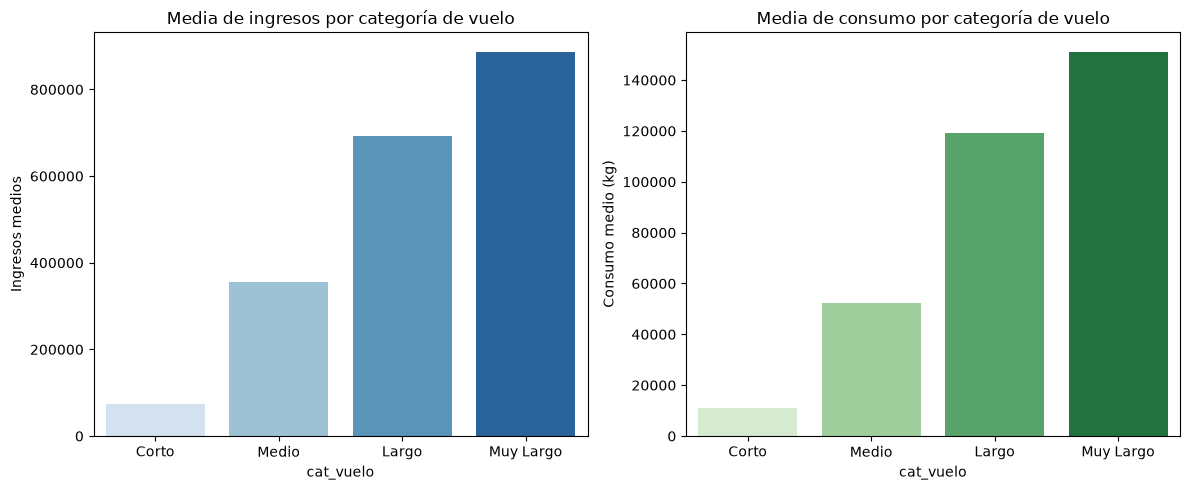

In [78]:
stats = viajes.groupby('cat_vuelo')[['ingresos', 'consumo_kg']].agg(['count', 'mean', 'std', 'min', 'max']).reset_index()
corr2 = viajes[['ingresos', 'consumo_kg']].corr()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=stats, x='cat_vuelo', y=('ingresos', 'mean'), ax=axes[0], palette='Blues')
axes[0].set_title('Media de ingresos por categoría de vuelo')
axes[0].set_ylabel('Ingresos medios')

sns.barplot(data=stats, x='cat_vuelo', y=('consumo_kg', 'mean'), ax=axes[1], palette='Greens')
axes[1].set_title('Media de consumo por categoría de vuelo')
axes[1].set_ylabel('Consumo medio (kg)')

plt.tight_layout()
plt.show()

Obtenemos la misma relación que antes: cuanto más largo es el vuelo, más ingresos genera y más combustible gasta.

### Extra:

#1 Consejos para encontrar "objetivos":

Si partes de un dataset que te parece interesante pero sin pregruntras claras, haz como hicimos con el dataset de Aviones. Describe, prioriza a ojo tus variables, realiza un análisis univariante completo, realiza un análisis bivariante ente las parejas de variables que te parecieron más intereantes. Llegados a este punto si el dataset tiene riqueza informativa, algo diferente tiene que haber aparecido (otra cosa es que sea interesante para ti :-)).  

Fíjate en lo que encontramos en el dataset de viajes: la empresa de más vuelos es la que menos ingresos tiene o la existencia clara de una línea de vuelos más eficientes en consumo que otros y otra de mayor ingresos por consumo. Lo siguiente es explorar esos puntos normalmente intentando contestar a: ¿por qué pasa?¿dónde,cuándo o cómo pasa?  

Busca esas "notas discordantes" en tu dataset, ya de por sí son mensajes del análisis. Ordénalas por importancia (importancia = impactan en ingresos, impactan en la calidad de la vida de las personas, impactan en el coste y poco más hay) e intenta entender por qué suceden esas notas discordantes, cómo solucionarlas o aprovecharlas y ya tienes objeetivos para el EDA; incluso si no encuentras respuesta siempre tendras esas notas discordantes, la conclusión de que no se puede avanzar con los datos que se tienen y los próximos pasos de encontrar más información para explicar lo que ocurre.

#2 Contestando a las preguntas de "Viajes".

- Necesitamos identificar esas líneas eficientes, para ello crea una variable que mida el ingreso por kilogramo consumido y otra que mida el kilogramo consumido por kilómetro. Haz el análisis univariante de las mismas intentando encontrar una diferencia clara entre viajes eficientes y no eficientes (que sabemos que existe). Fija un umbral para indicar si un viaje es supereficiente o si no lo es
- Crea esa variable de eficiencia binaria de eficiencia.
- Ahora haz el análisis bivariante de esa eficiencia y las compañías aéreas (queremos ver si realmente eso explica la situación de TabarAir). 
- Para nota: Hacer los análisis multivariante por compañía, eficiencia, tipo de avión y compañía, eficiencia, destino e incluso el de compañía, eficiencia, origen, destino.
- Con todo ello deberías poder encontrar si hay respuesta a la situación de TabarAir además de poder mostrar otros datos interesantes.